# 03 Quantum Reservoir Computing con sQUlearn

El reservorio no se entrena: codificar, evolucionar con una dinámica fija y aleatoria, medir observables y ajustar solo una lectura lineal. Ideal para intuir por qué QRC evita el coste del VQA.

Referencias: [guía QRC de sQUlearn](https://squlearn.github.io/user_guide/quantum_reservoir_computing.html) y handbook ([QML](https://iraitzm.github.io/qc-handbook/es/parts/qml/)).


In [1]:
!pip install -q squlearn scikit-learn matplotlib


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


## 1. La idea en una frase

QNN optimiza los pesos de un circuito parametrizado complejo. QRC deja ese circuito **fijo y aleatorio** (el reservorio) y solo entrena la lectura lineal sobre $M$ valores esperados. Menos quántica iterativa, más álgebra lineal clásica.


## 2. QRC para clasificación (lunas)

Codificamos con `ChebyshevPQC`, medimos 200 observables aleatorios y clasificamos con regresión lineal.


In [2]:
import numpy as np
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import MinMaxScaler

X, y = make_moons(n_samples=120, noise=0.12, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)
# El encoding de Chebyshev usa arccos: los datos deben vivir en [-1, 1]
scaler = MinMaxScaler((-0.9, 0.9))
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [3]:
from squlearn.encoding_circuit import ChebyshevPQC
from squlearn import Executor
from squlearn.qrc.qrc_classifier import QRCClassifier

pqc = ChebyshevPQC(num_qubits=8, num_layers=2)
pqc.draw('mpl', num_features=2)

executor = Executor()
qrc = QRCClassifier(pqc, executor=executor, ml_model='linear', num_operators=200)
qrc.fit(X_train, y_train)
print('QRC train:', round(qrc.score(X_train, y_train), 3))
print('QRC test: ', round(qrc.score(X_test, y_test), 3))

QRC train: 1.0
QRC test:  1.0


## 3. Frontera de decisión

¿Dónde ayuda el reservorio? Dibujemos qué ha aprendido la lectura lineal.


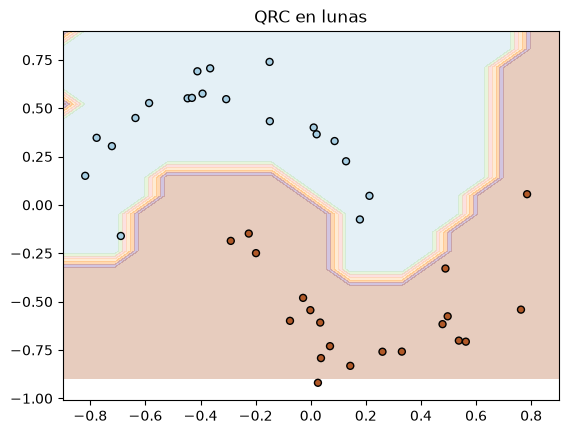

In [4]:
import matplotlib.pyplot as plt

# Malla gruesa a propósito: cada punto es una evaluación cuántica (~1 s)
# Mismo rango que el scaler: fuera de [-1, 1] el arccos de Chebyshev da NaN
xx, yy = np.meshgrid(np.linspace(-0.9, 0.9, 20), np.linspace(-0.9, 0.9, 20))
Z = qrc.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Paired)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=plt.cm.Paired, edgecolors='k', s=25, label='test')
plt.title('QRC en lunas'); plt.show()

## 4. QRC para regresión (onda)

Mismo esquema, otro cabezal: `QRCRegressor` sobre una senoide ruidosa.


In [5]:
from squlearn.encoding_circuit import HubregtsenEncodingCircuit
from squlearn.qrc import QRCRegressor

from sklearn.model_selection import train_test_split as tts

rng = np.random.default_rng(42)
Xr = np.arange(0.0, 1.0, 0.02)
yr = np.sin(2 * np.pi * Xr) + 0.1 * rng.standard_normal(Xr.shape)
# Split aleatorio (no por bloques): la lectura lineal interpola, no extrapola
Xr_train, Xr_test, yr_train, yr_test = tts(Xr.reshape(-1, 1), yr, test_size=0.33, random_state=42)

pqc_r = HubregtsenEncodingCircuit(num_qubits=6, num_layers=2)
qrc_r = QRCRegressor(pqc_r, executor=Executor(), ml_model='linear', num_operators=200)
qrc_r.fit(Xr_train, yr_train)
print('QRC regresión train R²:', round(qrc_r.score(Xr_train, yr_train), 3))
print('QRC regresión test  R²:', round(qrc_r.score(Xr_test, yr_test), 3))

QRC regresión train R²: 0.992
QRC regresión test  R²: 0.985


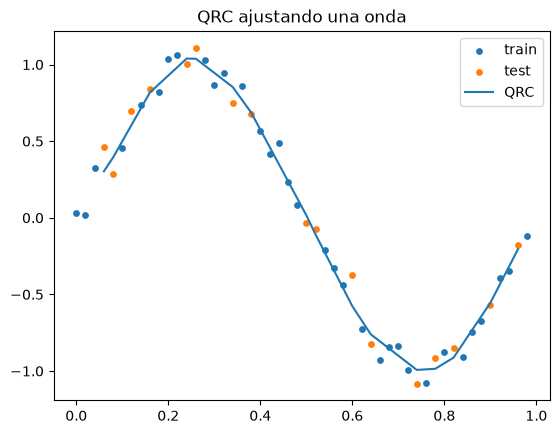

In [6]:
orden = np.argsort(Xr_test.ravel())
plt.scatter(Xr_train, yr_train, label='train', s=15)
plt.scatter(Xr_test, yr_test, label='test', s=15)
plt.plot(Xr_test[orden], qrc_r.predict(Xr_test[orden]), label='QRC')
plt.legend(); plt.title('QRC ajustando una onda'); plt.show()

## 5. Referencia clásica (para calibrar el asombro)

El mismo readout lineal sin reservorio cuántico: si el QRC no lo supera aquí, el dataset no necesitaba un espacio de Hilbert.


In [7]:
from sklearn.linear_model import LogisticRegression, LinearRegression

print('logística lunas test:', round(LogisticRegression().fit(X_train, y_train).score(X_test, y_test), 3))
print('lineal onda test R²:', round(LinearRegression().fit(Xr_train, yr_train).score(Xr_test, yr_test), 3))

logística lunas test: 0.925
lineal onda test R²: 0.646


## Para clase

- Tarea: bajad `num_operators` a 20 y repetid. ¿A partir de qué $M$ se degrada?
- Tarea: cambiad `ml_model` a `'kernel'` y comparad tiempos de ajuste.
